In [55]:
import random
def generate_random_value():
    return random.randint(0, 1)

def compute_fitness(individual):
    return sum(individual)

def create_individual(n):
    return [generate_random_value() for _ in range(n)]

def crossover(parent1, parent2, rate = 0.9):
    child1 = parent1.copy()
    child2 = parent2.copy()

    if random.random() < rate:

        for i in range(len(parent1)):
            if random.random() < 0.5:
                child1[i], child2[i] = child2[i], child1[i]

    return child1, child2

def mutation(individual, rate = 0.05):
    return [1 - val if random.random() < rate else val for val in individual]

def selection(population):
    # Chọn ngẫu nhiên 2 cá thể trong quần thể
    individual1, individual2 = random.sample(population, 2)

    if compute_fitness(individual1) > compute_fitness(individual2):
        return individual1
    else:
        return individual2 

In [ ]:
n = 100 #Length of each individual (binary string)
m = 100 #Population size

generations = 100 # Number of generations
elitism = 2 # Number of elite individuals to carry over
population =  [create_individual(n) for _ in range(m)]

finess_history = []
for gen in range(generations):
    population = sorted(population, key = compute_fitness, reverse = True)
    # Track the best fitness in this generation
    if gen % 10 == 0:
        best_finess = compute_fitness(population[0])
        finess_history.append(best_finess)
        print(f'Generation {gen} - Best Number of 1: {best_finess}')

    # Elitism: retain the best individuals
    new_population = population[:elitism]

    while len(new_population) < m:
        parent1 = selection(population)
        parent2 = selection(population)
        child1, child2 = crossover(parent1, parent2)
        new_population.append(mutation(child1))

        if len(new_population) < m:
            new_population.append(mutation(child2))
    population = new_population

best_individual = sorted(population, key = compute_fitness, reverse = True)[0]
print(f'Best individual: {best_individual}')
print(f'Best fitness (number of 1s): {compute_fitness(best_individual)}')
print(f'Fitness history : {finess_history}')

Generation 0 - Best Number of 1: 60
Generation 10 - Best Number of 1: 77
Generation 20 - Best Number of 1: 84
Generation 30 - Best Number of 1: 86
Generation 40 - Best Number of 1: 88
Generation 50 - Best Number of 1: 88
Generation 60 - Best Number of 1: 88
Generation 70 - Best Number of 1: 88
Generation 80 - Best Number of 1: 90
Generation 90 - Best Number of 1: 90
Best individual: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Best fitness (number of 1s): 90
Fitness history : [60, 77, 84, 86, 88, 88, 88, 88, 90, 90]


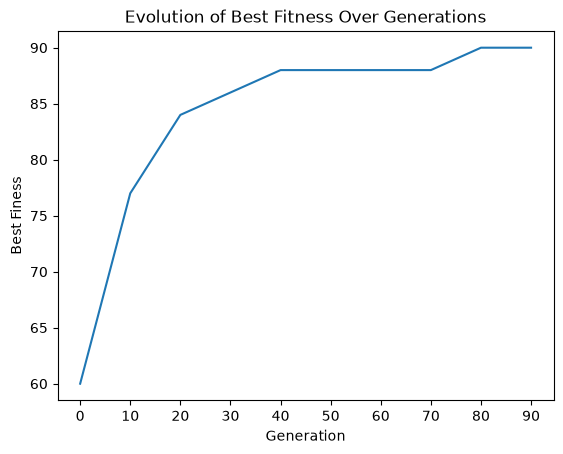

In [57]:
import matplotlib.pyplot as plt
plt.plot(finess_history)
plt.xlabel('Generation')
plt.xticks(ticks = range(0, len(finess_history), 1), labels=[str(i * 10) for i in range(len(finess_history))])
plt.ylabel('Best Finess')
plt.title('Evolution of Best Fitness Over Generations')
plt.show()